# CS08 - Real case B: least-cost sizing of a solar-battery-diesel mini-grid (Agadez region)

**Problem type:** energy access - sizing an isolated system at least cost, with real hourly
weather, and testing how the answer depends on the diesel price.

**Data:** NASA POWER hourly 2023 for Agadez (16.97 N, 7.99 E), PV via pvlib (or a
Renewables.ninja CSV if provided); temperature-driven demand, peak 2 MW; existing 2.5 MW
diesel genset; costs in `src/pscs/assumptions.py` (remote-site PV 1000 $/kW, battery
350 $/kWh + 200 $/kW, diesel 1.00 $/litre at 0.28 l/kWh).

## 1. The decision question
A town in the Agadez region is supplied only by diesel generators. Fuel is trucked over long
distances. **What mix of PV and batteries minimises the cost of electricity, how much
diesel does it save, and how robust is the answer to the fuel price?**

## 2. Exercise
1. Compute the cost of the diesel-only system (cost per kWh, litres, CO2).
2. Optimise PV and battery sizes over the 8760 hours of 2023.
3. Show a typical dry-season day and a monsoon day.
4. Repeat the optimisation for diesel at 0.8, 1.0, 1.2 and 1.4 $/litre. Conclusions?

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "pscs").exists())
sys.path.insert(0, str(ROOT / "src"))
import numpy as np
import pandas as pd
import pypsa
import matplotlib.pyplot as plt

import pscs
from pscs import assumptions as A
from pscs.plotting import ENTITY, SERIES, INK2, MUTED, save

DATA, FIG, TAB = pscs.setup()
PATH = DATA / "networks" / "agadez_minigrid_2023"
n0 = pypsa.Network(PATH)
demand = n0.loads_t.p_set["town"]
cf = n0.generators_t.p_max_pu["pv"]
E = demand.sum()
print(f"Demand {E:.0f} MWh/yr, peak {demand.max():.2f} MW; PV capacity factor {cf.mean():.1%}")
print(f"Diesel marginal cost at 1.00 $/l: {A.diesel_marginal_cost():.0f} $/MWh")

Demand 12445 MWh/yr, peak 2.00 MW; PV capacity factor 21.2%
Diesel marginal cost at 1.00 $/l: 300 $/MWh


In [2]:
def solve(diesel_price=A.DIESEL_PRICE, hybrid=True):
    n = pypsa.Network(PATH)
    n.generators.loc["diesel", "marginal_cost"] = A.diesel_marginal_cost(diesel_price)
    if not hybrid:
        n.generators.loc["pv", ["p_nom_extendable", "p_nom"]] = [False, 0.0]
        n.storage_units.loc["battery", ["p_nom_extendable", "p_nom"]] = [False, 0.0]
    st, cond = n.optimize(solver_name="highs", solver_options={"output_flag": False})
    assert st == "ok", cond
    g, s = n.generators, n.storage_units
    pv, bat = g.p_nom_opt["pv"], s.p_nom_opt["battery"]
    diesel = n.generators_t.p["diesel"]
    capex = pv * g.capital_cost["pv"] + bat * s.capital_cost["battery"]
    fuel = (diesel * g.marginal_cost["diesel"]).sum()
    avail = (pv * cf).sum()
    out = {"diesel price ($/l)": diesel_price, "PV (kW)": 1000 * pv, "battery (kW)": 1000 * bat,
           "battery (kWh)": 1000 * bat * A.BAT_HOURS,
           "renewable share (%)": 100 * (1 - diesel.sum() / E),
           "PV curtailed (%)": 100 * (1 - n.generators_t.p["pv"].sum() / avail) if avail else 0.0,
           "diesel (MWh)": diesel.sum(), "diesel (1000 litres)": diesel.sum() * A.DIESEL_SFC,
           "genset running hours": int((diesel > 1e-3).sum()),
           "CO2 (t)": diesel.sum() * A.DIESEL_CO2,
           "cost (k$/yr)": (capex + fuel) / 1e3, "LCOE ($/kWh)": (capex + fuel) / E / 1000}
    return out, n

base_diesel, _ = solve(hybrid=False)
base_hybrid, nh = solve()
res = pd.DataFrame({"diesel only": base_diesel, "optimal hybrid": base_hybrid}).T
res.to_csv(TAB / "cs08_base.csv")
res.round(3)

Writing constraints.:   0%|          | 0/10 [00:00<?, ?it/s]

Writing constraints.: 100%|██████████| 10/10 [00:00<00:00, 125.10it/s]

Writing continuous variables.:   0%|          | 0/4 [00:00<?, ?it/s]

Writing continuous variables.: 100%|██████████| 4/4 [00:00<00:00, 275.87it/s]

Writing constraints.:   0%|          | 0/14 [00:00<?, ?it/s]

Writing constraints.: 100%|██████████| 14/14 [00:00<00:00, 130.76it/s]

Writing constraints.: 100%|██████████| 14/14 [00:00<00:00, 129.30it/s]

Writing continuous variables.:   0%|          | 0/6 [00:00<?, ?it/s]

Writing continuous variables.: 100%|██████████| 6/6 [00:00<00:00, 278.56it/s]

,diesel price ($/l),PV (kW),battery (kW),battery (kWh),renewable share (%),PV curtailed (%),diesel (MWh),diesel (1000 litres),genset running hours,CO2 (t),cost (k$/yr),LCOE ($/kWh)
diesel only,1.0,0.00,0.000,0.000,0.000,0.000,12445.210,3484.659,8760.0,9209.455,3733.563,0.300
optimal hybrid,1.0,7508.01,4482.684,17930.735,93.812,11.666,770.123,215.634,773.0,569.891,2028.380,0.163


## 3. Two typical days of the optimal hybrid system

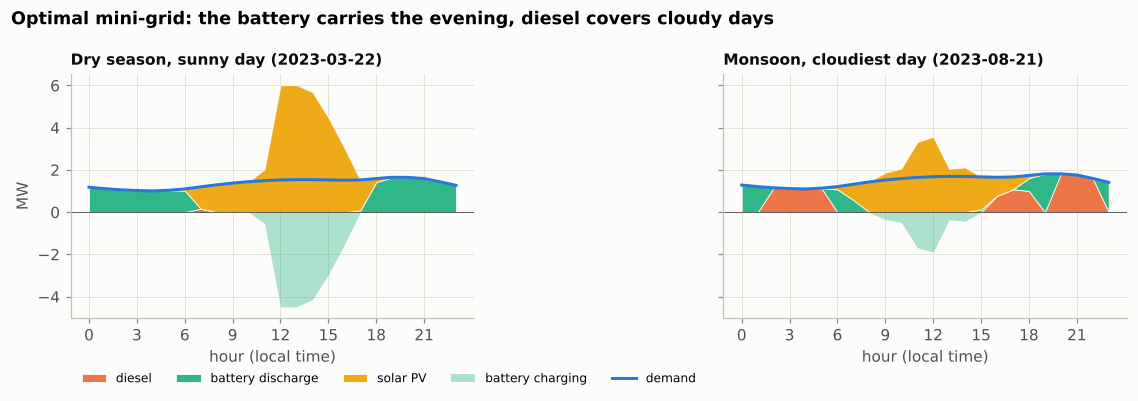

In [3]:
def day_plot(n, day, ax, title):
    idx = n.snapshots[n.snapshots.normalize() == pd.Timestamp(day)]
    h = idx.hour
    pv = n.generators_t.p.loc[idx, "pv"]
    bat = n.storage_units_t.p.loc[idx, "battery"]
    dsl = n.generators_t.p.loc[idx, "diesel"]
    ax.stackplot(h, dsl.values, bat.clip(lower=0).values, pv.values,
                 colors=[ENTITY["diesel"], ENTITY["battery"], ENTITY["solar"]],
                 labels=["diesel", "battery discharge", "solar PV"], alpha=0.9, edgecolor="#fcfcfb", lw=0.6)
    ax.fill_between(h, 0, bat.clip(upper=0).values, color=ENTITY["battery"], alpha=0.35, lw=0,
                    label="battery charging")
    ax.plot(h, n.loads_t.p_set.loc[idx, "town"].values, color=ENTITY["demand"], label="demand")
    ax.axhline(0, color=INK2, lw=0.6)
    ax.set_title(title, fontsize=10); ax.set_xticks(range(0, 24, 3)); ax.set_xlabel("hour (local time)")

cfd = cf.resample("D").sum()
dry = cfd[cfd.index.month.isin([2, 3])].idxmax().date()
wet = cfd[cfd.index.month.isin([7, 8])].idxmin().date()
fig, axes = plt.subplots(1, 2, figsize=(10.4, 3.8), sharey=True)
day_plot(nh, dry, axes[0], f"Dry season, sunny day ({dry})")
day_plot(nh, wet, axes[1], f"Monsoon, cloudiest day ({wet})")
axes[0].set_ylabel("MW")
axes[0].legend(loc="upper left", ncol=5, fontsize=8, bbox_to_anchor=(0, -0.18))
fig.suptitle("Optimal mini-grid: the battery carries the evening, diesel covers cloudy days",
             x=0.01, ha="left", fontweight="bold", fontsize=11.5)
fig.tight_layout()
save(fig, FIG / "cs08_typical_days.png")
fig

## 4. Sensitivity to the diesel price (question 4)

In [4]:
sens = pd.DataFrame([solve(p)[0] for p in [0.8, 1.0, 1.2, 1.4]]).set_index("diesel price ($/l)")
sens["LCOE diesel only ($/kWh)"] = [solve(p, hybrid=False)[0]["LCOE ($/kWh)"] for p in sens.index]
sens.to_csv(TAB / "cs08_sensitivity.csv")
sens.round(3)

Writing constraints.:   0%|          | 0/14 [00:00<?, ?it/s]

Writing constraints.:  93%|█████████▎| 13/14 [00:00<00:00, 115.40it/s]

Writing constraints.: 100%|██████████| 14/14 [00:00<00:00, 111.91it/s]

Writing continuous variables.:   0%|          | 0/6 [00:00<?, ?it/s]

Writing continuous variables.: 100%|██████████| 6/6 [00:00<00:00, 233.20it/s]

Writing constraints.:   0%|          | 0/14 [00:00<?, ?it/s]

... (27 outputs left out)

Writing constraints.: 100%|██████████| 10/10 [00:00<00:00, 134.62it/s]

Writing continuous variables.:   0%|          | 0/4 [00:00<?, ?it/s]

Writing continuous variables.: 100%|██████████| 4/4 [00:00<00:00, 285.42it/s]

,PV (kW),battery (kW),battery (kWh),renewable share (%),PV curtailed (%),diesel (MWh),diesel (1000 litres),genset running hours,CO2 (t),cost (k$/yr),LCOE ($/kWh),LCOE diesel only ($/kWh)
diesel price ($/l),,,,,,,,,,,,
0.8,7232.877,4369.815,17479.261,92.173,9.966,974.139,272.759,978,720.863,1980.422,0.159,0.244
1.0,7508.010,4482.684,17930.735,93.812,11.666,770.123,215.634,773,569.891,2028.380,0.163,0.300
1.2,7718.316,4623.659,18494.635,95.116,12.834,607.861,170.201,608,449.817,2067.461,0.166,0.356
1.4,7924.373,4776.820,19107.279,96.298,14.008,460.761,129.013,476,340.963,2096.821,0.168,0.412


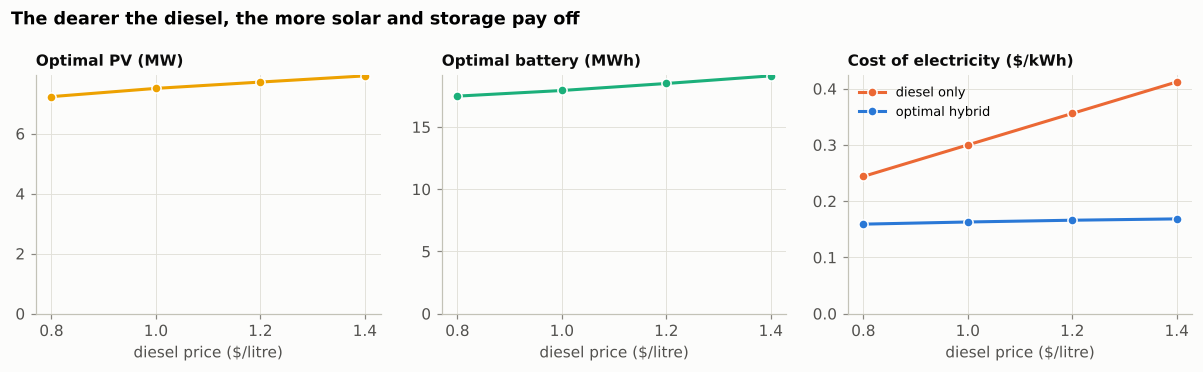

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(11.0, 3.4))
x = sens.index.values
axes[0].plot(x, sens["PV (kW)"] / 1000, "o-", color=ENTITY["solar"], markeredgecolor="white")
axes[0].set_title("Optimal PV (MW)", fontsize=10)
axes[1].plot(x, sens["battery (kWh)"] / 1000, "o-", color=ENTITY["battery"], markeredgecolor="white")
axes[1].set_title("Optimal battery (MWh)", fontsize=10)
axes[2].plot(x, sens["LCOE diesel only ($/kWh)"], "o-", color=ENTITY["diesel"], label="diesel only",
             markeredgecolor="white")
axes[2].plot(x, sens["LCOE ($/kWh)"], "o-", color=SERIES[0], label="optimal hybrid", markeredgecolor="white")
axes[2].set_title("Cost of electricity ($/kWh)", fontsize=10)
axes[2].legend(loc="upper left", fontsize=8.5)
for ax in axes:
    ax.set_xlabel("diesel price ($/litre)"); ax.set_xticks(x)
for ax in axes[:2]:
    ax.set_ylim(0, None)
axes[2].set_ylim(0, None)
fig.suptitle("The dearer the diesel, the more solar and storage pay off",
             x=0.01, ha="left", fontweight="bold", fontsize=11.5)
fig.tight_layout()
save(fig, FIG / "cs08_sensitivity.png")
fig

## 5. Interpretation and recommendations
* Diesel-only electricity costs about **0.30 $/kWh** in fuel alone at 1 $/litre - the
  reference against which solar and storage compete.
* The optimal hybrid supplies most of the energy from the sun, uses the battery for the
  evening and the night, and keeps the genset as a **back-up** for cloudy monsoon days. The
  cost per kWh falls markedly and the fuel bill (and the trucks on the road) shrink.
* The answer is **robust**: even at 0.8 $/litre the hybrid is cheaper; at higher prices the
  optimiser simply builds more PV and storage. Fuel-price risk is transferred to an
  up-front, predictable investment.
* **Keep the genset**: the monsoon days show that without it, the battery would have to
  be several times larger to cover a few cloudy days a year.

**For decision-makers:** a PV-battery-diesel hybrid is the least-cost option for isolated
towns in the Agadez region under all fuel prices tested. Priorities: secure financing of the
up-front cost (concessional loans, results-based grants), a tariff that recovers the cost,
and local maintenance capacity.

In [6]:
pscs.save_summary("cs08", {
    "demand_mwh": E, "peak_mw": demand.max(), "cf": cf.mean(),
    "base": res.to_dict(orient="index"), "sensitivity": sens.reset_index().to_dict(orient="records"),
    "dry_day": str(dry), "wet_day": str(wet),
})